# 估计精度与决策质量：更准的尾部风险估计，能带来更好的组合决策吗？

**问题**。01 篇发现 GARCH-EVT 等条件方法对单资产 ES 的预测明显更准；07 篇发现，到了组合层面，
用 ES 代替波动率几乎没有增量，GARCH 条件化的改进在 25bp 交易成本下消失。「估计更准」和「决策更好」之间的落差，
在真实数据上无法拆解：我们不知道真实分布，也就不知道哪个组合真的更优。

本篇在**真实分布已知**的模拟中回答：

1. 估计量 A 的风险估计误差比 B 小，A 支撑的决策是否一定更好？
2. 如果不是，估计误差中的哪一部分会传递到决策？
3. 答案是否取决于优化问题的形式（min ES 与 ES 平价）？
4. 在动态（GARCH）环境里，条件化带来的风险下降，与它带来的换手相比值多少？

**设计要点**

- 三个 DGP 的**协方差完全相同**（6 个资产，波动率与相关结构仿照 07 篇的资产宇宙），只有尾部不同：
  高斯、多元 t(4)（椭圆、厚尾、有尾部相关）、崩盘混合（非椭圆：小概率的「风险资产同跌、国债黄金上涨」日）。
  因此高斯插件规则（MV、ERC）在三个 DGP 下的「理想版本」是同一组权重，差别只在于它是否仍然是 ES 意义下的最优。
- 两类决策问题、每类两种估计方式：

| 决策问题 | 高斯插件（用样本协方差） | 非参数（用历史情景） | 真实最优（oracle） |
|---|---|---|---|
| min ES，单资产上限 40% | MV（最小方差） | MinES-HS（Rockafellar–Uryasev） | 用真实分布求解 |
| ES 平价（各资产 ES 贡献相等） | ERC（波动率平价） | ESP-HS（07 篇的 TRP-历史） | 用真实分布求解 |

- **决策质量**用真实分布评价：min ES 类看「决策后悔」= 真实 ES(ŵ) / 真实 ES(w\*) − 1；
  平价类看真实 ES 贡献偏离均等的程度 Σ|RC_i − 1/6|。**估计质量**看固定组合上 ES 估计的相对误差。
- 实验 A：独立同分布、单期，T 从 125 到 4000 日，每格 500 次重复。实验 B：GJR-GARCH 波动率，
  每月调仓、期间持有、计入交易成本，每个 DGP 40 条 10 年路径。

**一个可以先写下来的事实**。在椭圆分布族中，任何组合的 ES 都等于 k·√(w'Σw)，k 只取决于分布形状。所以 min ES ⇔ min 方差，
ES 平价 ⇔ 波动率平价：高斯插件对 ES **水平**的估计可能偏差很大（t 分布下低估约 10%），但这个偏差是一个常数倍数，
不改变组合之间的排序，因而**对决策没有影响**。决策只受估计误差中改变排序的那部分（下称「形状」误差）影响。

## 0 · 环境

模拟结果缓存在 `results/`（模拟数据，可以提交）。`RERUN = True` 时重跑全部模拟；
环境变量 `S09_QUICK=1` 时用极小的网格做冒烟测试。

In [1]:
import os
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%run ../../01_methods.ipynb

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9, "axes.grid": True, "grid.alpha": .3,
    "axes.spines.top": False, "axes.spines.right": False, "axes.unicode_minus": False,
    "font.sans-serif": ["PingFang SC", "Heiti TC", "Arial Unicode MS", "SimHei", "DejaVu Sans"],
})
# 两类估计/决策方式的固定配色：高斯（协方差）插件 = 蓝，非参数历史情景 = 橙，条件化 = 青，部分调整 = 黄
C_GAUSS, C_HS, C_COND, C_ADJ, C_REF = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8984"

RERUN = False                                   # True：忽略缓存，重新跑全部模拟（约 1–2 小时，8 核）
QUICK = os.environ.get("S09_QUICK") == "1"      # 冒烟测试：极小的网格，结果写到 *_quick 文件
RES = Path("results")
RES.mkdir(exist_ok=True)
FIG = Path("figures")
FIG.mkdir(exist_ok=True)


def cached(name, fn):
    """模拟结果缓存到 results/ 下；存在且 RERUN=False 时直接读取。"""
    path = RES / f"{name}{'_quick' if QUICK else ''}.csv.gz"
    if path.exists() and not RERUN:
        return pd.read_csv(path)
    df = fn()
    df.to_csv(path, index=False)
    return df


def mean_se(x):
    x = np.asarray(x, float)
    return x.mean(), x.std(ddof=1) / np.sqrt(len(x))

## 1 · 数据生成过程与理想决策

- 新息 z：单位方差、相关矩阵 CORR。t(4) 按 √((ν−2)/W) 缩放到单位方差。
  崩盘混合：每天以 1% 的概率出现一次 k 倍（k = 1 + Exp(1)）的联合冲击，方向为（−3, −3, −2.5, +1, +0.5, −2.5）个标准差，
  再整体做线性变换，使均值为 0、协方差严格等于 CORR。
- 真实 ES：椭圆族用解析式 k·√(w'Σw)；崩盘混合用固定的 200 万天样本。
- oracle：椭圆族直接是最小方差 / 波动率平价；崩盘混合在 200 万天样本上求解（ES 几乎光滑，用 SLSQP / L-BFGS-B）。

In [2]:
# ── 模拟用的资产宇宙与数据生成过程 ──────────────────────────────────────────
from numpy.linalg import cholesky

ASSETS = ["沪深300", "中证500", "标普500", "国债", "黄金", "原油"]
N_ASSETS = len(ASSETS)
ANN_VOL = np.array([0.25, 0.28, 0.18, 0.03, 0.15, 0.32])
DAYS = 244
SIG = ANN_VOL / np.sqrt(DAYS)
CORR = np.array([
    [1.00, 0.85, 0.25, -0.10, 0.05, 0.20],
    [0.85, 1.00, 0.20, -0.10, 0.05, 0.20],
    [0.25, 0.20, 1.00, -0.20, 0.05, 0.30],
    [-0.10, -0.10, -0.20, 1.00, 0.15, -0.10],
    [0.05, 0.05, 0.05, 0.15, 1.00, 0.25],
    [0.20, 0.20, 0.30, -0.10, 0.25, 1.00],
])
SIGMA = np.outer(SIG, SIG) * CORR
L_CORR = cholesky(CORR)
Q = 0.95
UPPER = 0.40          # 最小化类问题的单资产上限；风险平价类不设上限

# 崩盘混合：每天以 P_CRASH 的概率出现一次「联合崩盘」，风险资产按 CRASH_DIR 方向同时出现
# k 倍标准差的冲击（k = 1 + Exp(1)，均值 2），国债、黄金同时小幅上涨。之后整体线性变换，
# 使均值为 0、协方差严格等于 CORR —— 与高斯、t 的二阶矩完全相同，差别只在尾部。
CRASH_DIR = np.array([-3.0, -3.0, -2.5, 1.0, 0.5, -2.5])
_EK, _EK2 = 2.0, 5.0
CRASH_P = {"崩盘混合": 0.01, "崩盘·弱": 0.003, "崩盘·强": 0.03}   # 后两者只用于敏感性分析


def _crash_transform(p):
    m = p * _EK * CRASH_DIR
    cov = CORR + p * _EK2 * np.outer(CRASH_DIR, CRASH_DIR) - np.outer(m, m)
    return m, np.linalg.inv(cholesky(cov)).T @ L_CORR.T        # 行向量右乘：协方差 cov → CORR


_CRASH_TF = {k: _crash_transform(p) for k, p in CRASH_P.items()}

DGPS = ["高斯", "t(4)", "崩盘混合"]
NU = 4.0


def draw_innov(kind, n, rng):
    """n 天、单位方差、相关矩阵为 CORR 的新息（行 = 天）。"""
    z = rng.standard_normal((n, N_ASSETS)) @ L_CORR.T
    if kind == "高斯":
        return z
    if kind == "t(4)":
        w = rng.chisquare(NU, n)
        return z * np.sqrt((NU - 2) / w)[:, None]
    if kind in CRASH_P:
        m, A = _CRASH_TF[kind]
        k = (rng.random(n) < CRASH_P[kind]) * (1 + rng.exponential(1.0, n))
        return (z + k[:, None] * CRASH_DIR - m) @ A
    raise ValueError(kind)


# ── 真实 ES：椭圆分布用解析式，崩盘混合用固定的大样本 ───────────────────────
K_GAUSS = norm.pdf(norm.ppf(Q)) / (1 - Q)
_tq = student_t.ppf(Q, NU)
K_T = np.sqrt((NU - 2) / NU) * student_t.pdf(_tq, NU) / (1 - Q) * (NU + _tq ** 2) / (NU - 1)
K_ELLIPTIC = {"高斯": K_GAUSS, "t(4)": K_T}


def es_sample(x, q=Q):
    """样本 ES（损失为正）：最差 ⌈(1−q)n⌉ 个观测的平均损失。x 可以是 (n,) 或 (n, m)，按列计算。"""
    x = np.asarray(x, float)
    k = max(int(np.ceil((1 - q) * x.shape[0])), 1)
    part = np.partition(x, k - 1, axis=0)[:k]
    return -part.mean(axis=0)


class Truth:
    """一个 DGP 的真实风险泛函：真实 ES、ES 贡献，以及两类「理想决策」（oracle）。scale 为各资产的日波动率。"""

    def __init__(self, kind, scale=SIG, n_big=2_000_000, seed=12345):
        self.kind, self.scale = kind, np.asarray(scale, float)
        self.S = np.outer(self.scale, self.scale) * CORR
        if kind not in K_ELLIPTIC:
            self.Z = draw_innov(kind, n_big, np.random.default_rng(seed)) * self.scale
        self.w_min = self._oracle_min()
        self.w_par = self._oracle_parity()

    def es(self, w):
        w = np.atleast_2d(w)
        if self.kind in K_ELLIPTIC:
            return K_ELLIPTIC[self.kind] * np.sqrt(np.einsum("ij,jk,ik->i", w, self.S, w))
        return es_sample(self.Z @ w.T)

    def contributions(self, w):
        """真实 ES 的欧拉分解，返回各资产占组合 ES 的比例。"""
        w = np.asarray(w, float)
        if self.kind in K_ELLIPTIC:
            rc = w * (self.S @ w)
            return rc / rc.sum()
        port = self.Z @ w
        k = int(np.ceil((1 - Q) * len(port)))
        tail = np.argpartition(port, k - 1)[:k]
        rc = -w * self.Z[tail].mean(axis=0)
        return rc / rc.sum()

    def _oracle_min(self):
        if self.kind in K_ELLIPTIC:                                   # 椭圆族：min ES ⇔ min 方差
            return qp_min_var(self.S)
        return slsqp_min_es(self.Z)

    def _oracle_parity(self):
        if self.kind in K_ELLIPTIC:                                   # 椭圆族：ES 平价 ⇔ 波动率平价
            return erc_from_cov(self.S)
        return es_parity_big(self.Z[:400_000])


def qp_min_var(S, upper=UPPER):
    n = S.shape[0]
    res = minimize(lambda w: w @ S @ w, np.full(n, 1 / n), jac=lambda w: 2 * S @ w, method="SLSQP",
                   bounds=[(0, upper)] * n, constraints=[{"type": "eq", "fun": lambda w: w.sum() - 1}],
                   options={"maxiter": 500, "ftol": 1e-16})
    return res.x / res.x.sum()


def erc_from_cov(S):
    """波动率平价（Spinu 凸形式），用 L-BFGS-B 直接在 y 上求解。"""
    n = S.shape[0]
    b = np.full(n, 1 / n)
    Ss = S / np.diag(S).mean()
    f = lambda y: (0.5 * y @ Ss @ y - b @ np.log(y), Ss @ y - b / y)
    res = minimize(f, np.full(n, 1.0), jac=True, method="L-BFGS-B", bounds=[(1e-10, None)] * n,
                   options={"ftol": 1e-15, "gtol": 1e-12, "maxiter": 5000})
    return res.x / res.x.sum()


def slsqp_min_es(X, upper=UPPER, q=Q):
    """
    大样本（百万级）上的 min ES（带上限）。情景足够多时 ES(Xw) 几乎光滑，梯度是尾部情景的平均损失向量，
    直接用 SLSQP；比 Rockafellar–Uryasev LP 快得多（LP 在几十万情景时既慢又占内存）。
    """
    X = np.asarray(X, float)
    s = X.std(axis=0).mean()
    n = X.shape[1]
    k = int(np.ceil((1 - q) * X.shape[0]))

    def f(w):
        p = X @ w
        tail = np.argpartition(p, k - 1)[:k]
        return -p[tail].mean() / s, -X[tail].mean(axis=0) / s

    w0 = qp_min_var(np.cov(X[:200_000].T), upper)
    res = minimize(f, w0, jac=True, method="SLSQP", bounds=[(0, upper)] * n,
                   constraints=[{"type": "eq", "fun": lambda w: w.sum() - 1, "jac": lambda w: np.ones(n)}],
                   options={"maxiter": 300, "ftol": 1e-12})
    return res.x / res.x.sum()


def es_parity_big(X):
    """
    大样本上的 ES 平价：min ES(Xy) − Σ b ln y。ES 的次梯度是尾部情景的平均损失向量；
    样本足够大时目标几乎光滑，用 L-BFGS-B 即可。
    """
    X = np.asarray(X, float)
    X = X / X.std(axis=0).mean()
    n = X.shape[1]
    b = np.full(n, 1 / n)
    k = int(np.ceil((1 - Q) * X.shape[0]))

    def f(y):
        p = X @ y
        tail = np.argpartition(p, k - 1)[:k]
        return -p[tail].mean() - b @ np.log(y), -X[tail].mean(axis=0) - b / y

    res = minimize(f, np.full(n, 1.0), jac=True, method="L-BFGS-B", bounds=[(1e-10, None)] * n,
                   options={"ftol": 1e-14, "gtol": 1e-10, "maxiter": 5000})
    return res.x / res.x.sum()

In [3]:
# 理想决策（oracle）与「设定错误下限」：用真实协方差 Σ 求解的高斯插件规则（MV、ERC），在各 DGP 下离真正最优有多远。
# 三个 DGP 的协方差完全相同，所以这两个组合在三个 DGP 下是同一组权重；差别只在于它们是否仍是 ES 意义下的最优。
TRUTH = {k: Truth(k) for k in DGPS}
w_mv_true, w_erc_true = qp_min_var(SIGMA), erc_from_cov(SIGMA)
FLOOR_MIN = {k: tr.es(w_mv_true)[0] / tr.es(tr.w_min)[0] - 1 for k, tr in TRUTH.items()}
FLOOR_PAR = {k: np.abs(tr.contributions(w_erc_true) - 1 / N_ASSETS).sum() for k, tr in TRUTH.items()}
ann = np.sqrt(DAYS) * 100
check = pd.DataFrame({
    **{f"w*min·{a}": [tr.w_min[i] for tr in TRUTH.values()] for i, a in enumerate(ASSETS)},
    "真实 min ES（年化%）": [tr.es(tr.w_min)[0] * ann for tr in TRUTH.values()],
    "MV(真实Σ) 的超额 ES": [FLOOR_MIN[k] for k in TRUTH],
    **{f"w*par·{a}": [tr.w_par[i] for tr in TRUTH.values()] for i, a in enumerate(ASSETS)},
    "ERC(真实Σ) 的贡献偏离": [FLOOR_PAR[k] for k in TRUTH],
}, index=DGPS)
check.T.style.format("{:.3f}")

,高斯,t(4),崩盘混合
w*min·沪深300,0.061,0.061,0.041
w*min·中证500,0.021,0.021,0.002
w*min·标普500,0.209,0.209,0.196
w*min·国债,0.400,0.400,0.400
w*min·黄金,0.309,0.309,0.360
w*min·原油,0.000,0.000,0.000
真实 min ES（年化%）,14.157,15.544,14.857
MV(真实Σ) 的超额 ES,0.000,0.000,0.019
w*par·沪深300,0.048,0.048,0.041
w*par·中证500,0.044,0.044,0.037


## 2 · 实验 A：独立同分布下的估计与决策

In [4]:
# ── 实验 A：静态（独立同分布）环境下，估计精度与决策质量 ────────────────────
#
# 每次重复：从 DGP 抽 T 天收益 → 各决策规则给出权重 ŵ → 用真实分布评价 ŵ。
#   最小化类（目标：真实 ES 最小，单资产上限 40%）
#     MV        样本协方差 min 方差      = 高斯假设下的 min ES（参数法、可能设定错误）
#     MinES-HS  样本 ES 最小（RU 线性规划）= 非参数 min ES（设定正确、方差大）
#   平价类（目标：各资产对真实 ES 的贡献相等）
#     ERC       样本协方差的波动率平价   = 高斯假设下的 ES 平价
#     ESP-HS    样本情景的 ES 平价
#   EW 等权作参照。

def gauss_es(w, S):
    return K_GAUSS * np.sqrt(w @ S @ w)


RULES_MIN = ["MV", "MinES-HS"]
RULES_PAR = ["ERC", "ESP-HS"]


def decide(R):
    df = pd.DataFrame(R)
    return {
        "EW": np.full(N_ASSETS, 1 / N_ASSETS),
        "MV": min_variance(df, upper=UPPER).values,
        "MinES-HS": min_cvar(df, q=Q, upper=UPPER).values,
        "ERC": erc_weights(df).values,
        "ESP-HS": es_parity_weights(df, q=Q).values,
    }


def run_chunk_A(kind, T, reps, seed):
    tr = Truth(kind)
    es_min, es_par = tr.es(tr.w_min)[0], tr.es(tr.w_par)[0]
    fixed = {"EW": np.full(N_ASSETS, 1 / N_ASSETS), "w*min": tr.w_min, "w*par": tr.w_par}
    es_fixed = {k: tr.es(w)[0] for k, w in fixed.items()}
    rng = np.random.default_rng(seed)
    rows = []
    for r in range(reps):
        R = draw_innov(kind, T, rng) * SIG
        S_hat = np.cov(R.T)
        W = decide(R)
        for name, w in W.items():
            tes = tr.es(w)[0]
            rc = tr.contributions(w)
            if name in ("MV", "ERC"):
                est = gauss_es(w, S_hat)
            elif name in ("MinES-HS", "ESP-HS"):
                est = es_sample(R @ w)
            else:
                est = np.nan
            rows.append(dict(
                dgp=kind, T=T, rep=seed[-1] + r, rule=name,
                true_es=tes,
                regret_min=tes / es_min - 1,                     # 相对真实 min-ES 组合
                rc_err=np.abs(rc - 1 / N_ASSETS).sum(),          # 偏离真实 ES 平价的程度
                dist_min=np.abs(w - tr.w_min).sum(),
                dist_par=np.abs(w - tr.w_par).sum(),
                optimism=est / tes - 1,                          # 样本内自估 ES 相对真实 ES
                **{f"w{i}": w[i] for i in range(N_ASSETS)},
            ))
        # 估计精度：固定组合上，两种 ES 估计量各自的相对误差
        est = {}
        for pname, w in fixed.items():
            est[pname] = (gauss_es(w, S_hat), es_sample(R @ w))
            rows.append(dict(dgp=kind, T=T, rep=seed[-1] + r, rule=f"est@{pname}",
                             err_gauss=est[pname][0] / es_fixed[pname] - 1,
                             err_hs=est[pname][1] / es_fixed[pname] - 1))
        # 「形状」误差：两个组合 ES 之比的相对误差。整体尺度（水平）偏差在比值里抵消，
        # 只剩下会改变组合排序、从而影响决策的那部分误差。
        true_ratio = es_fixed["w*min"] / es_fixed["EW"]
        rows.append(dict(dgp=kind, T=T, rep=seed[-1] + r, rule="est@ratio",
                         err_gauss=est["w*min"][0] / est["EW"][0] / true_ratio - 1,
                         err_hs=est["w*min"][1] / est["EW"][1] / true_ratio - 1))
    return rows


def run_A(T_grid, n_reps, kinds=DGPS, chunk=50, n_jobs=-1):
    from joblib import Parallel, delayed

    tasks = [(k, T, min(chunk, n_reps - s), [9, *k.encode("utf-8"), T, s])
             for k in kinds for T in T_grid for s in range(0, n_reps, chunk)]
    out = Parallel(n_jobs=n_jobs, verbose=0)(delayed(run_chunk_A)(*t) for t in tasks)
    return pd.DataFrame([row for rows in out for row in rows])

In [5]:
T_GRID = [125, 500] if QUICK else [125, 250, 500, 1000, 2000, 4000]
N_REPS = 20 if QUICK else 500
resA = cached("expA", lambda: run_A(T_GRID, N_REPS))
DEC = resA[~resA.rule.str.startswith("est@")].copy()
EST = resA[resA.rule.str.startswith("est@")].copy()
print(len(resA), "行；", DEC.groupby(["dgp", "T"]).rep.nunique().min(), "次重复 / 格")

81000 行； 500 次重复 / 格


### 2.1 min ES：高斯插件与非参数，谁的决策更好？

In [6]:
def paired(df, a, b, col, index=("dgp", "T")):
    """a 与 b 两条规则在同一批样本上的指标之差（a − b）：均值与标准误。"""
    p = df[df.rule.isin([a, b])].pivot_table(index=[*index, "rep"], columns="rule", values=col)
    d = (p[a] - p[b]).groupby(level=list(index))
    return pd.DataFrame({"差": d.mean(), "se": d.std(ddof=1) / np.sqrt(d.count())})


def table_min(dec, kinds):
    m = dec[dec.rule.isin(RULES_MIN)].pivot_table(index=["dgp", "T"], columns="rule", values="regret_min") * 100
    d = paired(dec, "MinES-HS", "MV", "regret_min") * 100
    m["MinES−MV"] = d["差"]
    m["t"] = d["差"] / d["se"]
    return m.loc[kinds]


# 表 A1：最小化类。决策后悔 = 所选组合的真实 ES / 真实最优组合的 ES − 1（%）
tabA1 = table_min(DEC, DGPS)
tabA1.style.format("{:.2f}")

### 2.2 估计精度：水平误差与形状误差

In [7]:
# 表 A2：估计精度。固定组合（等权）上 ES 估计的相对误差：偏差与 RMSE（%），
# 以及「形状」误差：w*min 与等权两个组合 ES 之比的相对误差 —— 只有这一部分会改变组合的排序。
def est_table(est, kinds):
    out = {}
    for lab, rule in [("水平", "est@EW"), ("形状", "est@ratio")]:
        e = est[est.rule == rule].groupby(["dgp", "T"])
        for name, col in [("高斯", "err_gauss"), ("HS", "err_hs")]:
            out[(lab, name, "偏差")] = e[col].mean() * 100
            out[(lab, name, "RMSE")] = e[col].apply(lambda x: np.sqrt((x ** 2).mean())) * 100
    return pd.DataFrame(out).loc[kinds]


tabA2 = est_table(EST, DGPS)
tabA2.style.format("{:.1f}")

### 2.3 ES 平价：ERC 与 ESP-HS

In [8]:
# 表 A3：平价类。贡献偏离 = Σ|真实 ES 贡献占比 − 1/6|，0 表示完全实现 ES 平价
def table_par(dec, kinds):
    m = dec[dec.rule.isin(RULES_PAR)].pivot_table(index=["dgp", "T"], columns="rule", values="rc_err")
    d = paired(dec, "ESP-HS", "ERC", "rc_err")
    m["ESP−ERC"] = d["差"]
    m["t"] = d["差"] / d["se"]
    m["ERC 下限"] = [FLOOR_PAR.get(k, np.nan) for k, _ in m.index]
    return m.loc[kinds]


tabA3 = table_par(DEC, DGPS)
tabA3.style.format("{:.3f}")

### 2.4 图

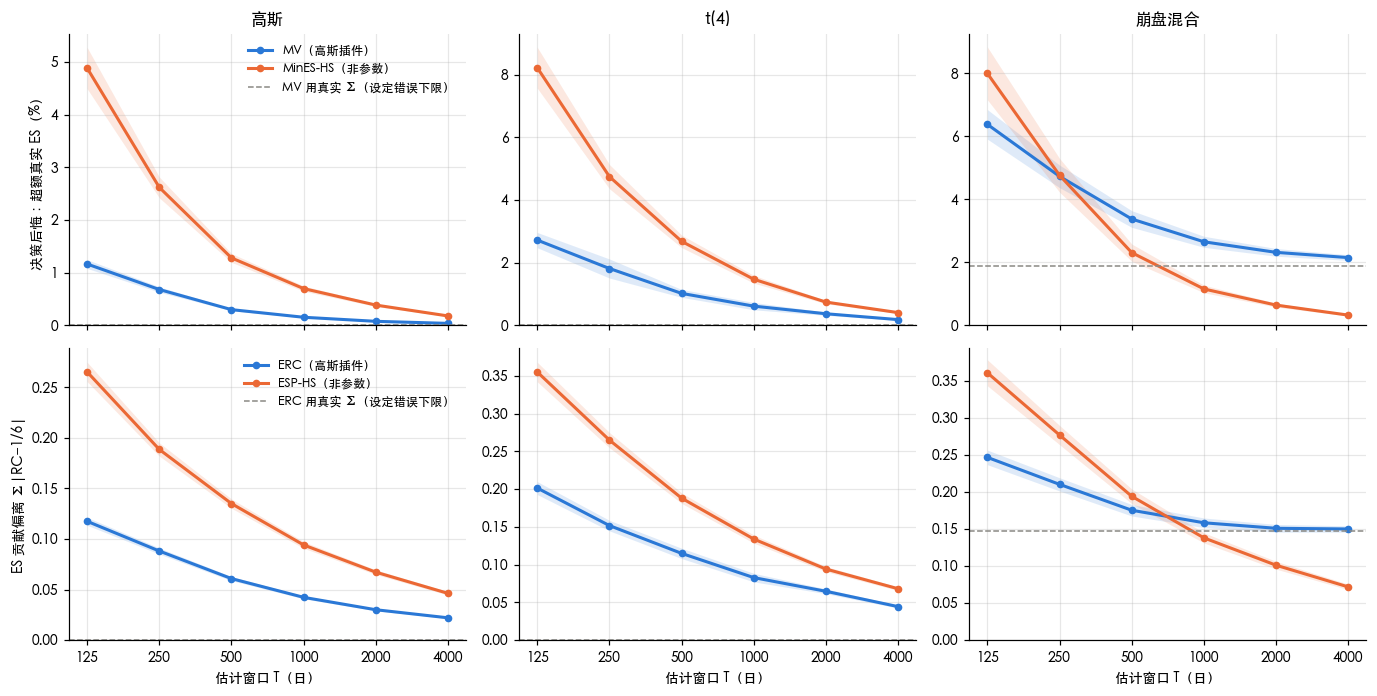

In [9]:
def band(ax, g, col, color, label, scale=1.0, ls="-"):
    s = g[col].agg(["mean", "std", "count"])
    m, se = s["mean"] * scale, s["std"] / np.sqrt(s["count"]) * scale
    ax.plot(m.index, m, color=color, lw=2, ls=ls, marker="o", ms=4, label=label)
    ax.fill_between(m.index, m - 2 * se, m + 2 * se, color=color, alpha=.15, lw=0)


def fig_A(dec, kinds, floors_min, floors_par, path=None):
    fig, axes = plt.subplots(2, len(kinds), figsize=(4.2 * len(kinds), 6.4), sharex=True)
    for j, k in enumerate(kinds):
        d = dec[dec.dgp == k]
        ax = axes[0, j]
        band(ax, d[d.rule == "MV"].groupby("T"), "regret_min", C_GAUSS, "MV（高斯插件）", 100)
        band(ax, d[d.rule == "MinES-HS"].groupby("T"), "regret_min", C_HS, "MinES-HS（非参数）", 100)
        ax.axhline(floors_min[k] * 100, color=C_REF, ls="--", lw=1, label="MV 用真实 Σ（设定错误下限）")
        ax.set_title(k)
        ax.set_ylabel("决策后悔：超额真实 ES（%）" if j == 0 else "")
        ax = axes[1, j]
        band(ax, d[d.rule == "ERC"].groupby("T"), "rc_err", C_GAUSS, "ERC（高斯插件）")
        band(ax, d[d.rule == "ESP-HS"].groupby("T"), "rc_err", C_HS, "ESP-HS（非参数）")
        ax.axhline(floors_par[k], color=C_REF, ls="--", lw=1, label="ERC 用真实 Σ（设定错误下限）")
        ax.set_ylabel("ES 贡献偏离 Σ|RC−1/6|" if j == 0 else "")
        ax.set_xscale("log")
        ax.set_xticks(T_GRID, [str(t) for t in T_GRID])
        ax.minorticks_off()
        ax.set_xlabel("估计窗口 T（日）")
    axes[0, 0].legend(fontsize=8, frameon=False)
    axes[1, 0].legend(fontsize=8, frameon=False)
    for ax in axes.flat:
        ax.set_ylim(bottom=0)
    fig.tight_layout()
    if path:
        fig.savefig(path, bbox_inches="tight")
    return fig


fig_A(DEC, DGPS, FLOOR_MIN, FLOOR_PAR, FIG / "fig_A_regret.pdf");

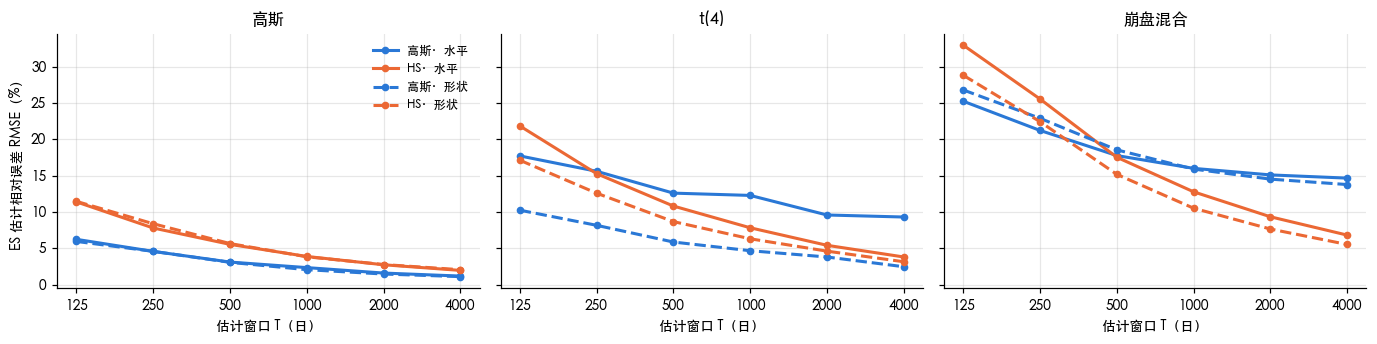

In [10]:
# 图 A2：估计精度的「水平」与「形状」。决策只受形状误差影响
fig, axes = plt.subplots(1, len(DGPS), figsize=(4.2 * len(DGPS), 3.2), sharey=True)
for ax, k in zip(axes, DGPS):
    e = EST[EST.dgp == k]
    for rule, ls, lab in [("est@EW", "-", "水平"), ("est@ratio", "--", "形状")]:
        g = e[e.rule == rule].groupby("T")
        for col, color, name in [("err_gauss", C_GAUSS, "高斯"), ("err_hs", C_HS, "HS")]:
            rm = g[col].apply(lambda x: np.sqrt((x ** 2).mean())) * 100
            ax.plot(rm.index, rm, color=color, ls=ls, lw=2, marker="o", ms=4, label=f"{name}·{lab}")
    ax.set_xscale("log")
    ax.set_xticks(T_GRID, [str(t) for t in T_GRID])
    ax.minorticks_off()
    ax.set_title(k)
    ax.set_xlabel("估计窗口 T（日）")
axes[0].set_ylabel("ES 估计相对误差 RMSE（%）")
axes[0].legend(fontsize=8, frameon=False)
fig.tight_layout()
fig.savefig(FIG / "fig_A_estimation.pdf", bbox_inches="tight");

### 2.5 敏感性：崩盘强度

把崩盘日概率从 1% 改为 0.3%（弱）和 3%（强），协方差仍然完全相同。T\* 是非参数规则此后始终优于高斯插件的最小窗口。

In [11]:
SENS = ["崩盘·弱", "崩盘混合", "崩盘·强"]
resS = cached("expA_sens", lambda: run_A(T_GRID, 20 if QUICK else 300, kinds=["崩盘·弱", "崩盘·强"]))
DEC_S = pd.concat([DEC[DEC.dgp == "崩盘混合"], resS[~resS.rule.str.startswith("est@")]])
EST_S = pd.concat([EST[EST.dgp == "崩盘混合"], resS[resS.rule.str.startswith("est@")]])
TRUTH_S = {k: TRUTH.get(k) or Truth(k) for k in SENS}
FLOOR_MIN_S = {k: tr.es(w_mv_true)[0] / tr.es(tr.w_min)[0] - 1 for k, tr in TRUTH_S.items()}
FLOOR_PAR_S = {k: np.abs(tr.contributions(w_erc_true) - 1 / N_ASSETS).sum() for k, tr in TRUTH_S.items()}


def crossover(tab, col, a, b):
    """最小的 T：规则 a 的均值低于 b，且之后的 T 都保持如此。"""
    out = {}
    for k, g in tab.groupby(level=0):
        g = g.droplevel(0)
        better = (g[a] < g[b])
        Ts = [T for T in g.index if better.loc[T:].all()]
        out[k] = min(Ts) if Ts else np.nan
    return pd.Series(out, name=col)


sens = pd.DataFrame({
    "崩盘日概率": [CRASH_P[k] for k in SENS],
    "MV 下限（%）": [FLOOR_MIN_S[k] * 100 for k in SENS],
    "ERC 下限": [FLOOR_PAR_S[k] for k in SENS],
}, index=SENS)
tS1, tS3 = table_min(DEC_S, SENS), table_par(DEC_S.assign(), SENS)
sens["MinES 胜过 MV 的 T*"] = crossover(tS1, "T*", "MinES-HS", "MV")
sens["ESP 胜过 ERC 的 T*"] = crossover(tS3, "T*", "ESP-HS", "ERC")
display(sens.style.format({"崩盘日概率": "{:.3f}", "MV 下限（%）": "{:.2f}", "ERC 下限": "{:.3f}"}))
display(tS1.style.format("{:.2f}"))
tS3.style.format("{:.3f}")

,崩盘日概率,MV 下限（%）,ERC 下限,MinES 胜过 MV 的 T*,ESP 胜过 ERC 的 T*
崩盘·弱,0.003,0.23,0.041,4000,nan
崩盘混合,0.010,1.89,0.147,500,1000.000000
崩盘·强,0.030,5.51,0.375,125,250.000000


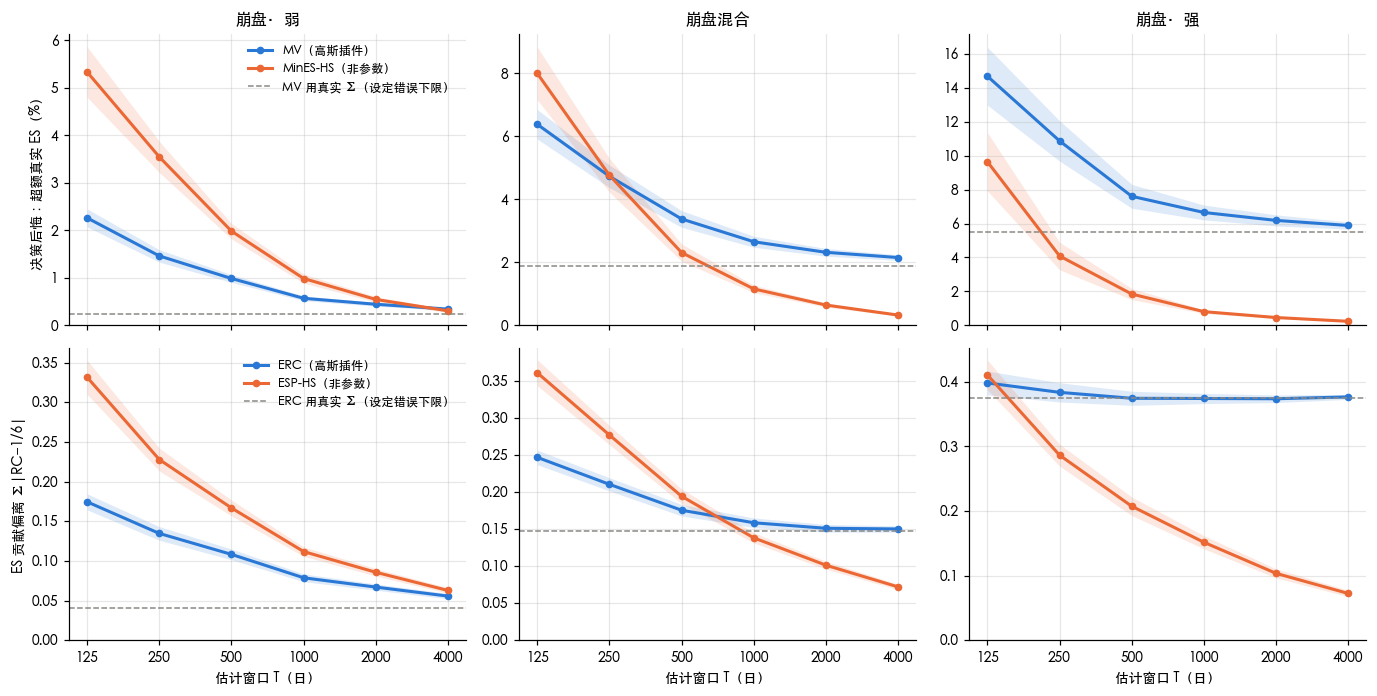

In [12]:
fig_A(DEC_S, SENS, FLOOR_MIN_S, FLOOR_PAR_S, FIG / "fig_A_crash_sensitivity.pdf");

## 3 · 实验 B：动态环境中的条件化、换手与成本

GJR-GARCH(1,1) 波动率（风险资产 α=0.04、γ=0.08、β=0.90；国债、黄金 α=0.05、γ=0.02、β=0.92），
无条件波动率与实验 A 相同；每个资产的期望超额收益使年化夏普为 0.3。真实的下一日条件分布已知，
所以每一天都能算出持仓的**真实条件 ES**和**真实条件方差**，期望夏普 = (日均 w'μ − 成本) / √(日均条件方差) × √244，
不受实现收益噪声的影响。规则与 07 篇一致（窗口 500 日，每 21 日调仓，期间持有、权重漂移）。

方差递推中的「新闻」项截断在 ±4σ（`NEWS_CAP`）。崩盘混合的新息可以低至 −25σ，不截断时 GJR 递推会让波动率爆炸到长期水平的上百倍
（第一版 40 条崩盘路径中有 2 条，峰值 57 倍和 117 倍，单条路径就足以主导均值）。截断后三个 DGP 的波动率峰值相近
（中位数约为长期水平的 3 倍，最大 6–8 倍）。截断只影响波动率的演化；当日收益仍用完整的新息，
真实的下一日条件分布 σ_{t+1} ⊙ z 不受影响。

In [13]:
# ── 实验 B：动态环境（GJR-GARCH 波动率）下的条件化、换手与交易成本 ──────────
#
# 收益 r_t = μ + σ_t ⊙ z_t。z_t 为实验 A 的三种新息（单位方差、相关 CORR），σ_{i,t} 按 GJR-GARCH(1,1) 演化：
#   σ²_{t+1} = ω + (α + γ·1[ε_t<0]) ε_t² + β σ²_t，ε_t = σ_t z_t
# 无条件波动率与实验 A 相同；期望超额收益 μ_i 让每个资产的年化夏普都等于 0.3。
# 真实的下一日条件分布已知：r_{t+1} | 过去 ~ μ + σ_{t+1} ⊙ z。
#
# 每 21 个交易日调仓一次，用过去 500 日数据：
#   -hist  直接用窗口内的历史收益（无条件）
#   -cond  多元过滤历史模拟（fhs_scenarios：GJR 过滤后按明日预测波动率重新缩放），与 07 篇相同
#   -adj   部分调整：w = w_持有 + η (ŵ_cond − w_持有)，η = 0.3。不改估计，只改决策规则，用来压低换手
# 调仓日之间买入持有，权重随价格漂移；交易成本按成交额 Σ|Δw| 计。
# oracle：调仓日用真实的下一日条件分布求解同一问题（月度调仓的理想决策）。

GARCH = {  # α, γ, β
    "风险": (0.04, 0.08, 0.90),
    "避险": (0.05, 0.02, 0.92),
}
_KIND = ["风险", "风险", "风险", "避险", "避险", "风险"]
G_ALPHA = np.array([GARCH[k][0] for k in _KIND])
G_GAMMA = np.array([GARCH[k][1] for k in _KIND])
G_BETA = np.array([GARCH[k][2] for k in _KIND])
G_OMEGA = SIG ** 2 * (1 - G_ALPHA - G_GAMMA / 2 - G_BETA)
MU = 0.3 * ANN_VOL / DAYS
LOOKBACK, HOLD, N_REB, BURN = 500, 21, 120, 1000
ETA = 0.3
COSTS_BP = [0, 10, 25, 50]
# 方差递推中的「新闻」截断在 ±4σ：崩盘混合的新息可达 −25σ，不截断时 GJR 会让波动率爆炸到长期水平的上百倍
# （第一版 40 条路径中有 2 条）。截断只影响波动率的演化；收益本身仍用完整的新息，真实条件分布 σ_{t+1}⊙z 不变。
NEWS_CAP = 4.0


def simulate_path(kind, rng):
    n = BURN + LOOKBACK + HOLD * N_REB
    z = draw_innov(kind, n, rng)
    sig = np.empty((n + 1, N_ASSETS))
    sig[0] = SIG
    eps = np.empty((n, N_ASSETS))
    news = np.clip(z, -NEWS_CAP, NEWS_CAP)
    for t in range(n):
        eps[t] = sig[t] * z[t]
        e = sig[t] * news[t]
        sig[t + 1] = np.sqrt(G_OMEGA + (G_ALPHA + G_GAMMA * (e < 0)) * e ** 2 + G_BETA * sig[t] ** 2)
    return MU + eps, sig          # sig[t] 是第 t 天收益的条件波动率（第 t−1 天收盘时已知）


class CondTruth:
    """给定条件波动率向量 s（下一日），真实的条件 ES 与 oracle。椭圆族解析，崩盘混合用固定新息样本。"""

    def __init__(self, kind, rng, n_mc=50_000):
        self.kind = kind
        if kind not in K_ELLIPTIC:
            self.Z = draw_innov(kind, n_mc, rng)

    def es(self, W, s):
        """W: (m, n) 一组权重，返回各组合真实下一日 ES（去掉均值后的风险部分；收益另由夏普计入）。"""
        W = np.atleast_2d(W)
        if self.kind in K_ELLIPTIC:
            S = np.outer(s, s) * CORR
            return K_ELLIPTIC[self.kind] * np.sqrt(np.einsum("ij,jk,ik->i", W, S, W))
        return es_sample((self.Z * s) @ W.T)

    def contributions(self, w, s):
        if self.kind in K_ELLIPTIC:
            S = np.outer(s, s) * CORR
            rc = w * (S @ w)
            return rc / rc.sum()
        X = self.Z * s
        port = X @ w
        k = int(np.ceil((1 - Q) * len(port)))
        tail = np.argpartition(port, k - 1)[:k]
        rc = -w * X[tail].mean(axis=0)
        return rc / rc.sum()

    def oracle(self, s):
        if self.kind in K_ELLIPTIC:
            S = np.outer(s, s) * CORR
            return qp_min_var(S), erc_from_cov(S)
        X = self.Z * s
        return slsqp_min_es(X), es_parity_big(X)


RULES_B = ["MV-hist", "MV-cond", "MinES-hist", "MinES-cond", "MinES-adj",
           "ERC-hist", "ERC-cond", "ESP-hist", "ESP-cond", "ESP-adj", "oracle-min", "oracle-par"]
FAMILY = {r: ("min" if r.startswith(("MV", "MinES", "oracle-min")) else "par") for r in RULES_B}


def run_path_B(kind, seed):
    import warnings
    warnings.filterwarnings("ignore")
    rng = np.random.default_rng(seed)
    r, sig = simulate_path(kind, rng)
    truth = CondTruth(kind, rng)
    m = len(RULES_B)
    hold = np.full((m, N_ASSETS), 1 / N_ASSETS)          # 当前持仓（漂移后）
    traded = np.zeros(m)
    sum_es, sum_mu, sum_var = np.zeros(m), np.zeros(m), np.zeros(m)
    rc_err = np.zeros(m)
    n_days = 0
    fc_rows = []
    w_ew = np.full(N_ASSETS, 1 / N_ASSETS)
    for j in range(N_REB):
        t = BURN + LOOKBACK - 1 + j * HOLD                     # 第 t 天收盘后调仓，t+1 起生效
        win = pd.DataFrame(r[t - LOOKBACK + 1: t + 1])
        fhs = fhs_scenarios(win)
        s_next = sig[t + 1]
        o_min, o_par = truth.oracle(s_next)
        tgt = {
            "MV-hist": min_variance(win, upper=UPPER).values,
            "MV-cond": min_variance(fhs, upper=UPPER).values,
            "MinES-hist": min_cvar(win, q=Q, upper=UPPER).values,
            "MinES-cond": min_cvar(fhs, q=Q, upper=UPPER).values,
            "ERC-hist": erc_weights(win).values,
            "ERC-cond": erc_weights(fhs).values,
            "ESP-hist": es_parity_weights(win, q=Q).values,
            "ESP-cond": es_parity_weights(fhs, q=Q).values,
            "oracle-min": o_min, "oracle-par": o_par,
        }
        for adj, base in (("MinES-adj", "MinES-cond"), ("ESP-adj", "ESP-cond")):
            h = hold[RULES_B.index(adj)]
            tgt[adj] = h + ETA * (tgt[base] - h) if j > 0 else tgt[base]
        new = np.array([tgt[k] for k in RULES_B])
        if j > 0:
            traded += np.abs(new - hold).sum(axis=1)
        hold = new.copy()
        # 平价类：调仓当日（下一日条件分布下）各资产 ES 贡献偏离均等的程度
        rc_err += np.array([np.abs(truth.contributions(w, s_next) - 1 / N_ASSETS).sum() for w in hold])
        # 预测精度：等权组合下一日 ES 的三种预测，对照真实条件 ES
        true_es_ew = truth.es(w_ew, s_next)[0]
        X_h, X_c = win.values - win.values.mean(0), fhs.values - fhs.values.mean(0)
        fc_rows.append(dict(
            dgp=kind, path=seed[-1], j=j, true=true_es_ew,
            高斯_hist=K_GAUSS * np.sqrt(w_ew @ np.cov(X_h.T) @ w_ew),
            HS_hist=es_sample(X_h @ w_ew),
            高斯_cond=K_GAUSS * np.sqrt(w_ew @ np.cov(X_c.T) @ w_ew),
            HS_cond=es_sample(X_c @ w_ew),
        ))
        for d in range(t + 1, t + 1 + HOLD):
            s = sig[d]
            S = np.outer(s, s) * CORR
            sum_es += truth.es(hold, s)
            sum_mu += hold @ MU
            sum_var += np.einsum("ij,jk,ik->i", hold, S, hold)
            g = hold @ r[d]
            hold = hold * (1 + r[d]) / (1 + g)[:, None]
            n_days += 1
    years = n_days / DAYS
    rows = []
    for i, name in enumerate(RULES_B):
        row = dict(dgp=kind, path=seed[-1], rule=name, family=FAMILY[name],
                   mean_es=sum_es[i] / n_days,
                   turnover=traded[i] / 2 / years,                  # 年化单边换手
                   rc_err=rc_err[i] / N_REB)
        for c in COSTS_BP:
            mu_net = (sum_mu[i] - c / 1e4 * traded[i]) / n_days
            row[f"sharpe_{c}"] = mu_net / np.sqrt(sum_var[i] / n_days) * np.sqrt(DAYS)
        rows.append(row)
    return rows, fc_rows


def run_B(n_paths, kinds=DGPS, n_jobs=-1):
    from joblib import Parallel, delayed

    tasks = [(k, [7, *k.encode("utf-8"), p]) for k in kinds for p in range(n_paths)]
    out = Parallel(n_jobs=n_jobs, verbose=0)(delayed(run_path_B)(*t) for t in tasks)
    res = pd.DataFrame([row for rows, _ in out for row in rows])
    fc = pd.DataFrame([row for _, rows in out for row in rows])
    return res, fc

In [14]:
if QUICK:
    N_REB = 6
N_PATHS = 2 if QUICK else 40


def _run_B():
    res, fc = run_B(N_PATHS)
    fc.to_csv(RES / f"expB_forecast{'_quick' if QUICK else ''}.csv.gz", index=False)
    return res


resB = cached("expB", _run_B)
fcB = pd.read_csv(RES / f"expB_forecast{'_quick' if QUICK else ''}.csv.gz")
print(resB.groupby("dgp").path.nunique().to_dict(), "条路径；每条", N_REB, "次调仓")

{'t(4)': 40, '崩盘混合': 40, '高斯': 40} 条路径；每条 120 次调仓


In [15]:
# 表 B1：预测精度。等权组合下一日 95% ES 的四种预测，对照真实条件 ES：log(预测/真实) 的偏差与 RMSE
FC = ["高斯_hist", "HS_hist", "高斯_cond", "HS_cond"]
lr = np.log(fcB[FC].div(fcB["true"], axis=0))
lr["dgp"] = fcB["dgp"]
tabB1 = pd.concat({"偏差": lr.groupby("dgp")[FC].mean(), "RMSE": lr.groupby("dgp")[FC].apply(lambda x: np.sqrt((x ** 2).mean()))}, axis=1)
(tabB1.loc[DGPS] * 100).style.format("{:.1f}")

In [16]:
# 表 B2：决策质量。真实条件 ES 的日均值（年化%）、相对同类 oracle 的超额 ES、平价偏离、年化单边换手、
# 以及按真实条件分布计算的期望夏普（成本 0/10/25/50bp）
B = resB.copy()
B["ES(年化%)"] = B.mean_es * np.sqrt(DAYS) * 100
orc = B[B.rule.str.startswith("oracle")].set_index(["dgp", "path", "family"]).mean_es
B["超额ES(%)"] = (B.mean_es / orc.reindex(pd.MultiIndex.from_frame(B[["dgp", "path", "family"]])).values - 1) * 100
cols = ["ES(年化%)", "超额ES(%)", "rc_err", "turnover"] + [f"sharpe_{c}" for c in COSTS_BP]
tabB2 = B.groupby(["dgp", "rule"])[cols].mean().reindex(pd.MultiIndex.from_product([DGPS, RULES_B]))
tabB2.style.format("{:.3f}")

In [17]:
# 表 B3：关键对照（逐路径配对差的均值与 t 值）
def paired_B(a, b, col):
    p = B.pivot_table(index=["dgp", "path"], columns="rule", values=col)
    d = (p[a] - p[b]).groupby(level=0)
    return d.mean(), d.mean() / (d.std(ddof=1) / np.sqrt(d.count()))


PAIRS = [("条件化：ERC-cond − ERC-hist", "ERC-cond", "ERC-hist"),
         ("换成 ES：ESP-cond − ERC-cond", "ESP-cond", "ERC-cond"),
         ("换成 ES：MinES-cond − MV-cond", "MinES-cond", "MV-cond"),
         ("部分调整：ESP-adj − ESP-cond", "ESP-adj", "ESP-cond"),
         ("部分调整：MinES-adj − MinES-cond", "MinES-adj", "MinES-cond")]
rows = {}
for lab, a, b in PAIRS:
    for col in ["超额ES(%)", "rc_err", "turnover", "sharpe_0", "sharpe_25", "sharpe_50"]:
        m, t = paired_B(a, b, col)
        for k in DGPS:
            rows.setdefault((lab, k), {})[col] = f"{m[k]:+.3f} ({t[k]:+.1f})"
tabB3 = pd.DataFrame(rows).T
tabB3

超额ES(%)          rc_err        turnover        sharpe_0       sharpe_25       sharpe_50
条件化：ERC-cond − ERC-hist     高斯     -3.213 (-13.8)  -0.201 (-51.4)  +0.374 (+52.2)  +0.026 (+29.0)  -0.018 (-14.9)  -0.062 (-34.0)
                            t(4)    -1.777 (-6.8)  -0.122 (-41.4)  +0.450 (+46.8)  +0.023 (+20.5)  -0.035 (-19.7)  -0.093 (-34.0)
                            崩盘混合    -1.538 (-4.8)  -0.071 (-16.6)  +0.429 (+53.2)  +0.026 (+15.4)  -0.024 (-15.7)  -0.075 (-40.3)
换成 ES：ESP-cond − ERC-cond   高斯      +0.616 (+1.7)  +0.056 (+25.0)   +0.022 (+9.7)   -0.002 (-6.9)  -0.005 (-12.0)  -0.007 (-14.2)
                            t(4)    +0.023 (+0.1)  +0.060 (+26.8)  +0.028 (+10.7)   -0.004 (-5.8)  -0.007 (-12.8)  -0.010 (-17.9)
                            崩盘混合  -10.287 (-24.3)   +0.005 (+0.7)   -0.011 (-3.2)   -0.004 (-8.2)  -0.007 (-15.9)  -0.011 (-17.9)
换成 ES：MinES-cond − MV-cond  高斯     +1.021 (+20.3)   -0.001 (-0.3)   +0.027 (+2.6)   -0.002 (-3.8)   -0.003 (-4.1)   -0.005 (-3.1)
                            t(4)   +1.657 (+13.9)   -0.001 (-0.1)   +0.038 (+3.4)   -0.003 (-4.2)   -0.004 (-4.6)   -0.006 (-3.4)
                            崩盘混合    -1.375 (-9.9)  +0.102 (+20.9)   -0.080 (-5.8)  -0.030 (-28.7)  -0.022 (-21.5)   -0.015 (-7.9)
部分调整：ESP-adj − ESP-cond     高斯     +2.417 (+21.0)  +0.075 (+39.4)  -0.365 (-59.6)  -0.010 (-24.8)  +0.032 (+41.7)  +0.075 (+56.0)
                            t(4)   +2.288 (+18.1)  +0.029 (+18.0)  -0.430 (-56.0)  -0.009 (-13.4)  +0.046 (+36.3)  +0.102 (+49.1)
                            崩盘混合   +2.597 (+16.7)  +0.033 (+19.8)  -0.382 (-61.8)  -0.012 (-14.2)  +0.037 (+39.6)  +0.086 (+59.5)
部分调整：MinES-adj − MinES-cond 高斯     +1.795 (+19.7)  -0.068 (-20.2)  -0.814 (-58.2)  -0.008 (-15.3)  +0.054 (+46.3)  +0.117 (+55.1)
                            t(4)    +0.944 (+8.8)  -0.090 (-20.3)  -0.906 (-55.8)   -0.003 (-4.3)  +0.072 (+49.6)  +0.148 (+58.5)
                            崩盘混合   +1.362 (+13.2)  -0.079 (-24.4)  -0.869 (-53.2)   -0.004 (-6.0)  +0.065 (+43.5)  +0.134 (+49.3)

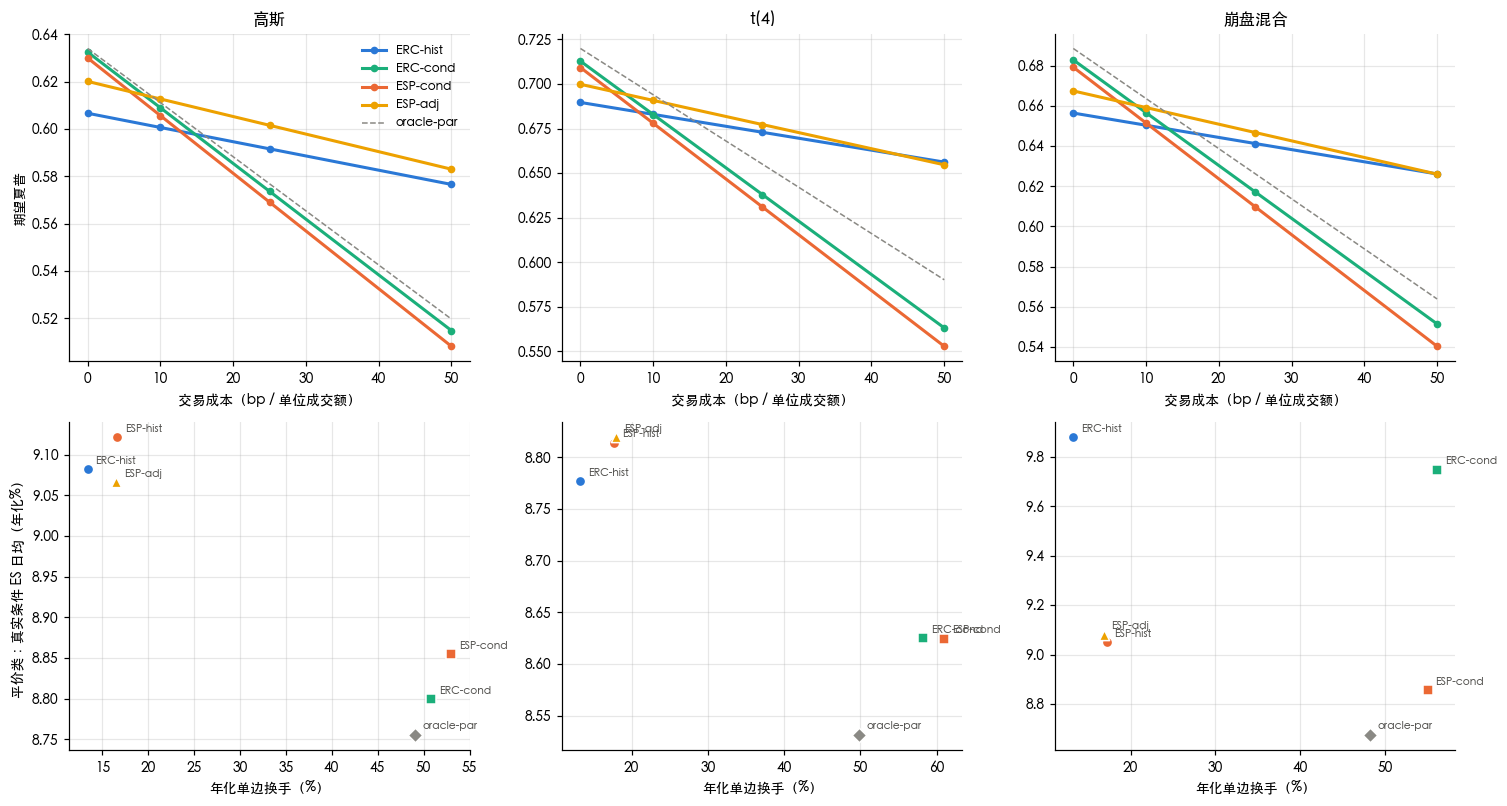

In [18]:
# 图 B：平价类规则的期望夏普随交易成本的变化（上），以及真实条件 ES 与换手（下）
fig, axes = plt.subplots(2, len(DGPS), figsize=(4.6 * len(DGPS), 7.4))
series = [("ERC-hist", C_GAUSS, "-"), ("ERC-cond", C_COND, "-"), ("ESP-cond", C_HS, "-"), ("ESP-adj", C_ADJ, "-")]
for j, k in enumerate(DGPS):
    t = tabB2.loc[k]
    ax = axes[0, j]
    for rule, color, ls in series:
        ax.plot(COSTS_BP, [t.loc[rule, f"sharpe_{c}"] for c in COSTS_BP], color=color, ls=ls, lw=2, marker="o", ms=4, label=rule)
    ax.plot(COSTS_BP, [t.loc["oracle-par", f"sharpe_{c}"] for c in COSTS_BP], color=C_REF, ls="--", lw=1, label="oracle-par")
    ax.set_title(k)
    ax.set_xlabel("交易成本（bp / 单位成交额）")
    ax.set_ylabel("期望夏普" if j == 0 else "")
    ax = axes[1, j]
    for rule, color, mk in [("ERC-hist", C_GAUSS, "o"), ("ERC-cond", C_COND, "s"), ("ESP-hist", C_HS, "o"),
                            ("ESP-cond", C_HS, "s"), ("ESP-adj", C_ADJ, "^"), ("oracle-par", C_REF, "D")]:
        x, y = t.loc[rule, "turnover"] * 100, t.loc[rule, "ES(年化%)"]
        ax.scatter(x, y, color=color, marker=mk, s=45, edgecolor="white", lw=1, zorder=3)
        ax.annotate(rule, (x, y), fontsize=7, xytext=(5, 3), textcoords="offset points", color="#52514e")
    ax.set_xlabel("年化单边换手（%）")
    ax.set_ylabel("平价类：真实条件 ES 日均（年化%）" if j == 0 else "")
axes[0, 0].legend(fontsize=8, frameon=False)
fig.tight_layout()
fig.savefig(FIG / "fig_B_costs.pdf", bbox_inches="tight");

## 4 · 结论

**1. 估计更准不等于决策更好，决定决策的是「形状」误差。** t(4) 下，T ≥ 250 时历史法（HS）对 ES 水平的估计比高斯插件更准
（T = 1000：RMSE 7.8% 对 12.3%）；但用它做 min ES，决策后悔反而是高斯插件 MV 的 2–3 倍（1.47% 对 0.62%），
平价偏离也更大（0.134 对 0.083）。原因是高斯插件的误差几乎全是**水平偏差**（稳定低估约 9%），它在组合之间是一个常数倍数，
不改变排序；在比值（形状）上，高斯插件没有偏差、方差更小（RMSE 4.6% 对 6.3%）。在全部 3 个 DGP、6 个窗口中，
「形状 RMSE 谁更小」与「决策谁更好」的排序都一致（崩盘混合 T = 250 时两者都几乎相等），「水平 RMSE 谁更小」则在 t(4) 的 5 个窗口里给出相反的结论。

**2. 尾部信息只有在改变排序时才对决策有用，而且需要足够的样本才能用上。** 椭圆族中，min ES 与 min 方差、ES 平价与波动率平价是同一个问题，
非参数规则只是更嘈杂的同一个估计，**在任何样本量下都更差**（所有 t 值 > 11）。崩盘混合是非椭圆的，高斯插件有不随样本消失的形状偏差（+13%），
于是有一个**设定错误下限**：MV 即使知道真实 Σ，超额 ES 也有 1.9%；ERC 的 ES 贡献偏离为 0.147（国债承担的尾部风险被低估）。
这是一个偏差-方差权衡：非参数规则在 T ≥ 500（min ES）或 T ≥ 1000（ES 平价）之后才胜出。

**3. 平价问题比最小化问题需要更多数据。** 同一个 DGP 下，ESP-HS 胜过 ERC 所需的窗口是 MinES-HS 胜过 MV 的约 2 倍
（崩盘混合：1000 对 500；强崩盘：250 对 125；弱崩盘：>4000 对 4000）。ES 平价要求每个资产的**边际** ES 贡献都估计准确，
而 min ES 只需要找到最优点附近的组合。这解释了 07 篇的结果：500 日窗口的 TRP-历史与普通风险平价几乎没有差别，
在模拟中，除非尾部结构强到「每年 7 次联合崩盘日」，500 日窗口都不足以让 ES 平价胜出。

**4. 胜出所需的样本量取决于尾部结构有多强。** 崩盘日概率从 0.3%、1% 到 3%，设定错误下限从 0.2%、1.9% 到 5.5%，
T\* 从 4000、500 到 125 日。弱尾部结构下，非参数 ES 需要 16 年日频数据才勉强追平高斯插件。

**5. 动态环境中，条件化让预测准得多，但决策的净收益很小，并在 10–15bp 成本时归零。** GARCH 过滤后，等权组合下一日 ES 预测的
log 误差 RMSE 从 18–29% 降到 5–22%（表 B1）。决策上，ERC-cond 比 ERC-hist 更接近真实的条件 ES 平价（偏离降低 0.07–0.20），
期望夏普在不计成本时高 0.023–0.026；但年化单边换手多出 37–45 个百分点。成本为 25bp 时，夏普差变为 −0.018 至 −0.035，
50bp 时为 −0.06 至 −0.09，三个 DGP 都显著（|t| > 14）。这与 07 篇在真实数据上的发现方向一致
（07 篇不计成本的改进更大，约 +0.11，同样在 25bp 时消失）。

**6. 用 ES 代替波动率，改变的是尾部风险，而不是夏普。** 崩盘混合下，ESP-cond 的真实条件 ES 比 ERC-cond 低 9%（8.86% 对 9.75%，t = −24），
期望夏普只低 0.004；椭圆族下 ES 平价反而离目标更远（偏离 +0.06）。07 篇用夏普比较 TRP 与风险平价、得到「没有增量」，
模拟提示这个评价指标本身可能看不到 ES 平价的作用：它重新分配了尾部风险，而夏普只看方差。

**7. 把交易规则改得保守，比把估计改得更准更有用。** 部分调整（每次只走 30% 的距离）把换手降低 37–43 个百分点，
不计成本时只损失 0.009–0.012 的夏普；25bp 时比完全调整高 0.032–0.046，在三个 DGP 下都是平价类中最高的，
甚至高于「每月按真实条件分布求解」的 oracle-par（例如高斯：0.602 对 0.577）。这说明单期 oracle 在有成本时并不是最优决策：
**决策问题本身应该包含成本**，而不只是在更准的风险估计上逐期重新求解。min ES 类的结论相同（MinES-adj 在 25bp 时比 MinES-cond 高 0.054–0.072）。

**对研究问题的回答。** 在本篇的设定中，「哪个模型对风险估计得更准」不是决定决策价值的量。决定决策价值的是：
(i) 估计误差中改变组合排序的那部分；(ii) 优化问题对这部分误差的敏感程度（平价比最小化更敏感）；
(iii) 决策规则怎样把估计变化转化为交易。这三点都可以在真实数据中检验，也是后续研究的方向（见 README）。